# Online Retail — Business Questions and Sales Analysis

**Dataset:** UCI Online Retail. The source contains invoice-level product lines from a UK online gift retailer.

**Project goal:** Answer business questions with transparent Pandas analysis, explain the evidence, and present a simple dashboard. This is a descriptive analysis project; it does not train a machine-learning model.

**Important grain:** one row is one product line on an invoice. An invoice with five products has multiple rows. Customer analysis has a different grain: one row per identified customer.


## Project roadmap

1. Business context and analytical questions
2. Data understanding and quality
3. Transaction features and sales table
4. Customer features and RFM segments
5. Product, time, and country analysis
6. Customer relationships and co-purchase
7. Outlier review, findings, limitations, and dashboard


## 1. Business Context and Questions

**Business context.** The company is a UK-registered, non-store ("purely online") retailer that sells
unique all-occasion gift items. A large share of its customers are wholesalers who buy in bulk, alongside
ordinary individual shoppers — this matters, because it means we should *expect* some very large orders
that are completely legitimate, not just outliers to be deleted.

**Dataset context.** Each row is one *product line* inside an *invoice* — i.e. if a customer buys 3
different products in one order, that is 3 rows sharing one `InvoiceNo`. This distinction between
"row", "invoice/order" and "customer" is the single most important thing to keep straight in this
notebook, because every metric we compute lives at one specific grain.

**Analytical objective.** Turn raw transaction logs into decision-ready insight about:
- **Customers** — who is valuable, who is at risk of churning, how do they behave?
- **Products** — what actually drives revenue vs. what merely moves in volume?
- **Time** — when does demand spike, and when is it quiet?
- **Geography** — which countries behave like different "markets"?
- **Structure** — do products get bought together? Are there outliers that change the story?

**Key business questions we will explicitly answer:**
1. Which customers generate the most value, and which are slipping away?
2. Are "best-selling" and "most valuable" products the same thing?
3. When during the day/week/year should the business staff up or run promotions?
4. Which countries are high-volume vs. high-value, and how should that change strategy?
5. Which products tend to sell together, and could that inform bundling?
6. Are extreme transactions data errors, or real (and valuable) wholesale behavior?

**Limitations to keep in mind throughout:**
- This is a **single year** of data (Dec 2010 – Dec 2011) from **one retailer** — patterns here are
  not automatically true for other businesses or other years.
- We have **no cost/margin data**, so "revenue" is not the same as "profit".
- ~25% of rows have **no CustomerID** (guest/unregistered checkouts) — customer-level conclusions only
  ever describe the *identified* customer base, not every transaction.
- Everything below is **descriptive and correlational**. We will say so explicitly every time we are
  tempted to imply causation.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.io as pio
from itertools import combinations
from collections import Counter

%matplotlib inline
pio.renderers.default = "notebook"

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

import warnings
warnings.filterwarnings("ignore")

RNG = np.random.default_rng(42)  

In [2]:
from pathlib import Path
DATA_PATH = Path('online_retail.csv.gz')
df_raw = pd.read_csv(DATA_PATH, compression='gzip')
df_raw['InvoiceDate'] = pd.to_datetime(df_raw['InvoiceDate'], errors='coerce')
print(f"Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()


Raw shape: 541,909 rows x 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


## 2. Data Understanding

**Business question:** What does one row represent, what is the dataset scale, and what are the column types?

Before touching quality issues or building features, we need a mental map of the dataset: what grain
is each column at, what type should it be, and what's the overall scale of the business it describes?

In [3]:
df_raw.info()
df_raw[[('Quantity'),('UnitPrice')]].describe()
for i in ['InvoiceNo','StockCode','Description','Quantity','InvoiceDate','UnitPrice','CustomerID','Country']:
    print(f"{df_raw[i].nunique()} unique values in {i}")

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB
25900 unique values in InvoiceNo
4070 unique values in StockCode
4223 unique values in Description
722 unique values in Quantity
23260 unique values in InvoiceDate
1630 unique values in UnitPrice
4372 unique values in CustomerID
38 unique values in Country


In [4]:
n_rows = len(df_raw)
n_invoices = df_raw['InvoiceNo'].nunique()
n_customers = df_raw['CustomerID'].nunique()
n_products = df_raw['StockCode'].nunique()
n_countries = df_raw['Country'].nunique()
date_min = df_raw['InvoiceDate'].min()
date_max = df_raw['InvoiceDate'].max()
span_days = (date_max - date_min).days

print(f"Rows: {n_rows:,} | Invoices: {n_invoices:,} | Known customers: {n_customers:,}")
print(f"Products: {n_products:,} | Countries: {n_countries:,}")
print(f"Data coverage: {date_min:%Y-%m-%d} to {date_max:%Y-%m-%d} ({span_days} days)")


Rows: 541,909 | Invoices: 25,900 | Known customers: 4,372
Products: 4,070 | Countries: 38
Data coverage: 2010-12-01 to 2011-12-09 (373 days)


## 3. Data Quality Investigation

**Business question:** Which quality issues could distort sales conclusions, and which rows should remain in each analytical table?

**Why this section matters before any "real" analysis:** if we compute RFM or revenue on dirty data,
every downstream number is wrong, and we won't know it. For each issue below we (1) detect it,
(2) quantify it, (3) explain *why* it exists, (4) decide what to do, and only then (5) apply the fix.

A key mindset for this section: **an unusual value is not automatically an error.** A £3,000 single
transaction looks extreme for a gift shop — but this retailer explicitly serves wholesalers, so it may
be a completely legitimate bulk order. We investigate before we delete anything.

<Axes: >

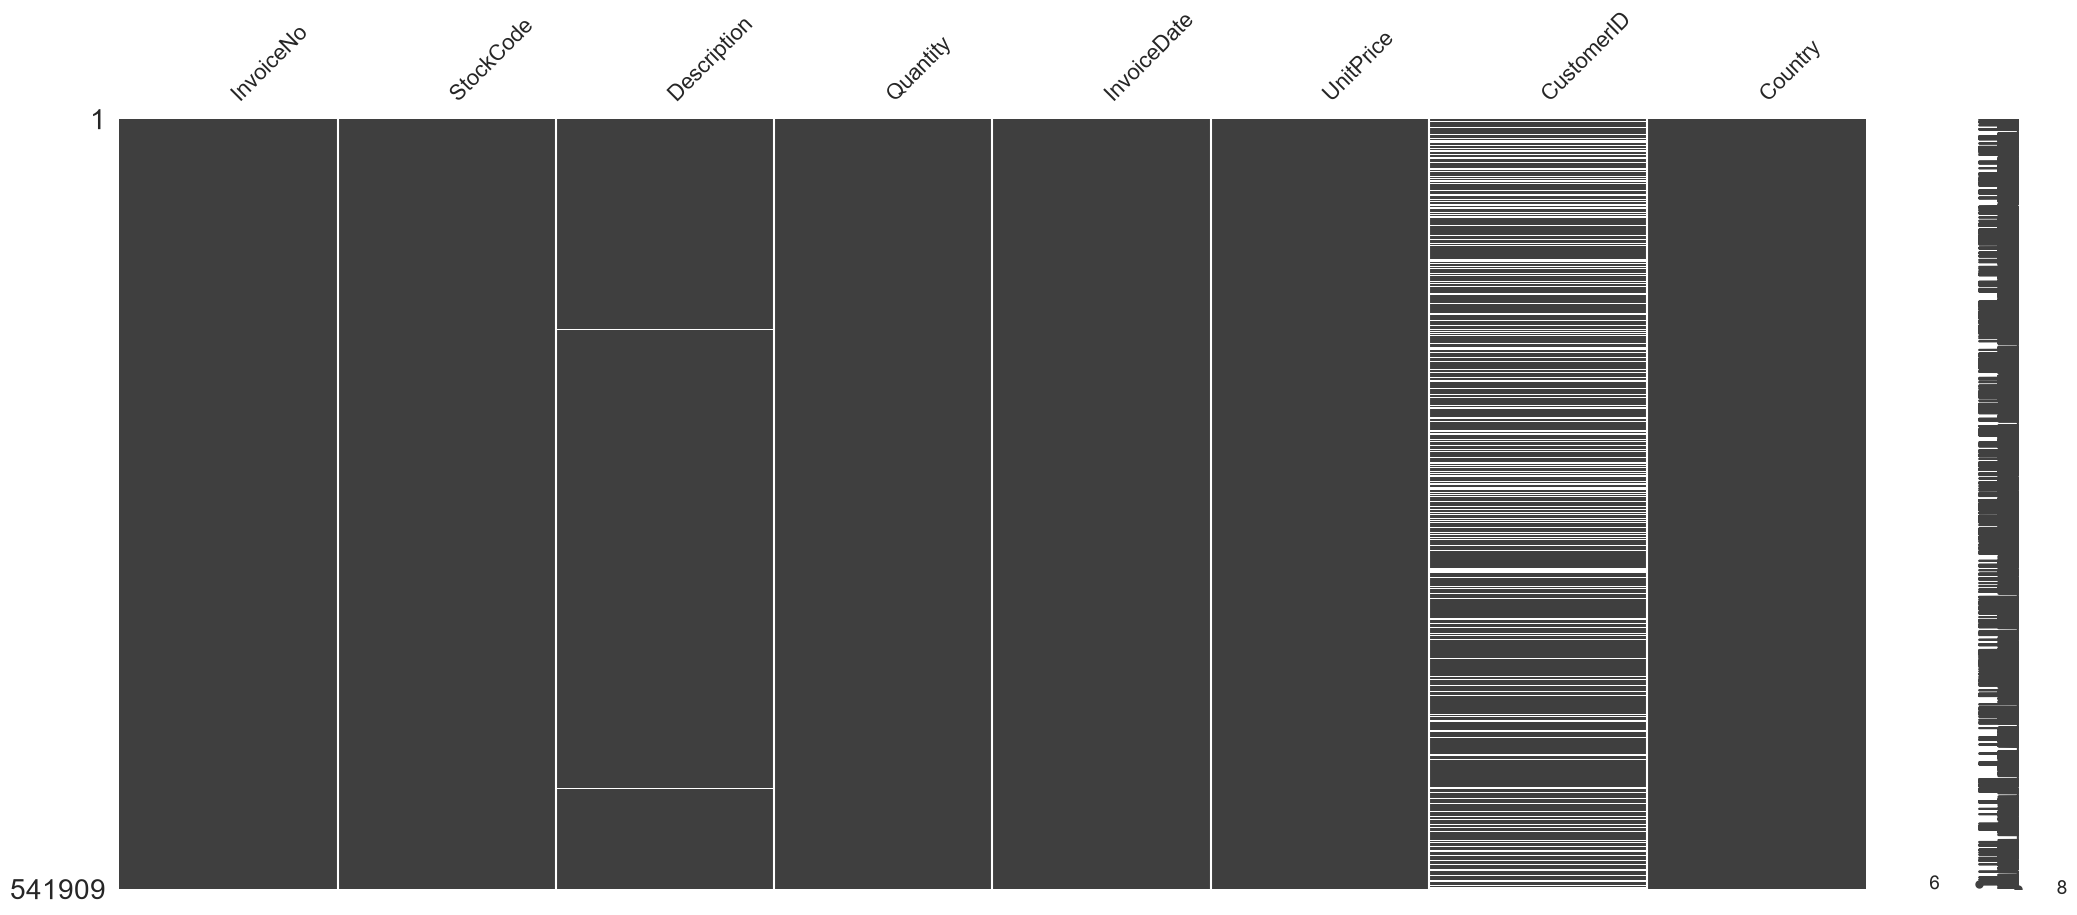

In [5]:
import missingno as msno
msno.matrix(df_raw)

In [6]:
dup_raws = df_raw.duplicated().sum()
is_cancel = df_raw['InvoiceNo'].astype(str).str.upper().str.startswith('C')
neg_qty = df_raw['Quantity'] <= 0
non_positive_price = df_raw['UnitPrice'] <= 0
non_product_codes = {'POST', 'D', 'M', 'BANK CHARGES', 'DOT', 'C2', 'CRUK', 'PADS', 'AMAZONFEE', 'S'}
isnon_product = df_raw['StockCode'].astype(str).str.upper().isin(non_product_codes)

print('Duplicate rows:', f'{dup_raws:,}')
print('Cancellation rows:', f'{is_cancel.sum():,}')
print('Non-positive quantities (not coded as cancellation):', f'{(neg_qty & ~is_cancel).sum():,}')
print('Non-positive prices:', f'{non_positive_price.sum():,}')
print('Service/non-merchandise rows:', f'{isnon_product.sum():,}')
print('Unknown customer IDs:', f"{df_raw['CustomerID'].isna().sum():,}")


Duplicate rows: 5,268
Cancellation rows: 9,288
Non-positive quantities (not coded as cancellation): 1,336
Non-positive prices: 2,517
Service/non-merchandise rows: 2,913
Unknown customer IDs: 135,080


In [7]:
df_raw[neg_qty & ~is_cancel][['InvoiceNo','StockCode','Description','Quantity','InvoiceDate','UnitPrice','CustomerID','Country']].info()

<class 'pandas.DataFrame'>
Index: 1336 entries, 2406 to 538919
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    1336 non-null   str           
 1   StockCode    1336 non-null   str           
 2   Description  474 non-null    str           
 3   Quantity     1336 non-null   int64         
 4   InvoiceDate  1336 non-null   datetime64[us]
 5   UnitPrice    1336 non-null   float64       
 6   CustomerID   0 non-null      float64       
 7   Country      1336 non-null   str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 93.9 KB


In [8]:
def clean_data(df):
    out = df.drop_duplicates().copy()
    out['IsCancelled'] = out['InvoiceNo'].astype(str).str.upper().str.startswith('C')
    out['IsNonProduct'] = out['StockCode'].astype(str).str.upper().isin(non_product_codes)
    out['IsZeroOrNegPrice'] = out['UnitPrice'] <= 0
    out['Description'] = out['Description'].fillna('Unknown')

    # Returns, negative adjustments and invalid dates are not positive merchandise sales.
    sales_mask = (
        ~out['IsCancelled'] & ~out['IsNonProduct'] & ~out['IsZeroOrNegPrice']
        & out['Quantity'].gt(0) & out['InvoiceDate'].notna()
        & out['InvoiceNo'].notna() & out['StockCode'].notna()
    )
    df_sales = out.loc[sales_mask].copy()
    return out, df_sales

df_clean, df_sales = clean_data(df_raw)
print(f'Cleaned rows (including cancellations): {len(df_clean):,}')
print(f'Positive merchandise sales rows: {len(df_sales):,}')


Cleaned rows (including cancellations): 536,641
Positive merchandise sales rows: 522,569


## 4. Feature Engineering — Transaction Level

**Business question:** Which transaction-level fields do we need to answer sales, product, and timing questions?

We now enrich every row of `df_sales` with derived fields. Each one exists to answer a specific later
question — we are not creating features "because we can".

| Feature | Why it exists |
|---|---|
| `Revenue` | `Quantity x UnitPrice` — the single most important derived number in the whole notebook |
| `Year / Quarter / Month / Week / Day / Hour` | lets us `groupby` at any time granularity in Section 8 |
| `DayName`, `MonthName` | human-readable labels for charts |
| `IsWeekend` | working-day vs weekend demand is a recurring business question |

In [9]:
df_sales["Revenue"]=df_sales['Quantity'] * df_sales['UnitPrice']
df_sales
dt = df_sales['InvoiceDate']
df_sales['year'] = dt.dt.year
df_sales['Quarter'] = dt.dt.quarter
df_sales['month'] = dt.dt.month
df_sales['MonName'] = dt.dt.strftime('%b')
df_sales['Day'] = dt.dt.day
df_sales['DayofWeek'] = dt.dt.dayofweek
df_sales['DayName'] = dt.dt.strftime('%a')
df_sales['Hour'] = dt.dt.hour
df_sales['week'] = dt.dt.isocalendar().week
df_sales['IsWeekend'] = df_sales['DayofWeek'].isin([5,6])
print(df_sales['Revenue'].sum())
df_sales.head()

10258967.19


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,IsNonProduct,IsZeroOrNegPrice,Revenue,year,Quarter,month,MonName,Day,DayofWeek,DayName,Hour,week,IsWeekend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,False,False,False,15.30,2010,4,12,Dec,1,2,Wed,8,48,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,False,False,20.34,2010,4,12,Dec,1,2,Wed,8,48,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,False,False,False,22.00,2010,4,12,Dec,1,2,Wed,8,48,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,False,False,20.34,2010,4,12,Dec,1,2,Wed,8,48,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,False,False,20.34,2010,4,12,Dec,1,2,Wed,8,48,False


## 5. Customer-Level Feature Table

**Business question:** Which customers generate the most value, how often do they order, and how recently did they purchase?

**Why aggregate to the customer level at all?** Every row so far describes *one line of one order*.
To answer "who are our best customers?" we must change grain — we are no longer describing individual
purchases, we are describing *people*. This is the most important conceptual shift in the notebook:
`groupby("CustomerID")` collapses thousands of transaction rows into one row per human/business.

We restrict this table to rows with a known `CustomerID` (Section 3 decision) — a customer-level table
cannot describe a customer we don't know the identity of.

In [10]:
df_clean.groupby(['InvoiceNo'])['CustomerID'].nunique(dropna=False).sort_values(ascending=False)

InvoiceNo
536365     1
536366     1
536367     1
536368     1
536369     1
          ..
C581484    1
C581490    1
C581499    1
C581568    1
C581569    1
Name: CustomerID, Length: 25900, dtype: int64

In [11]:
df_raw.groupby('InvoiceNo')['CustomerID'].transform('first')

0        17,850.00
1        17,850.00
2        17,850.00
3        17,850.00
4        17,850.00
            ...   
541904   12,680.00
541905   12,680.00
541906   12,680.00
541907   12,680.00
541908   12,680.00
Name: CustomerID, Length: 541909, dtype: float64

In [12]:
invoice_customers = df_raw.groupby(['InvoiceNo'])['CustomerID'].transform('first')
can_fill = df_raw['CustomerID'].isna() & df_raw['InvoiceNo'].notna()
can_fill.sum()
cust_sales = df_sales.dropna(subset=['CustomerID'])

In [13]:
df_raw[df_raw['CustomerID'].isnull()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
541536,581498,85099B,JUMBO BAG RED RETROSPOT,5,2011-12-09 10:26:00,4.13,NaN,United Kingdom
541537,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,2011-12-09 10:26:00,4.13,NaN,United Kingdom
541538,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,2011-12-09 10:26:00,4.96,NaN,United Kingdom
541539,581498,85174,S/4 CACTI CANDLES,1,2011-12-09 10:26:00,10.79,NaN,United Kingdom


In [14]:
df_sales.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'IsCancelled', 'IsNonProduct',
       'IsZeroOrNegPrice', 'Revenue', 'year', 'Quarter', 'month', 'MonName',
       'Day', 'DayofWeek', 'DayName', 'Hour', 'week', 'IsWeekend'],
      dtype='str')

In [15]:
snap_date= df_sales['InvoiceDate'].max()+pd.Timedelta(days=1)
snap_date

customer_df=cust_sales.groupby('CustomerID').agg(
    total_revenue=('Revenue','sum'),
    num_of_orders=('InvoiceNo','nunique'),
    num_of_items=('Quantity','sum'),
    unique_products=('StockCode','nunique'),
    first_purchases=('InvoiceDate','min'),
    last_purchases=('InvoiceDate','max'),
    country=('Country','first')  
).reset_index()

customer_df['average_order_value']=customer_df['total_revenue']/customer_df['num_of_orders']
customer_df['average_quantity_per_order']=customer_df['num_of_items']/customer_df['num_of_orders']
customer_df['lifetime_days']=(customer_df['last_purchases']-customer_df['first_purchases']).dt.days
customer_df

,CustomerID,total_revenue,num_of_orders,num_of_items,unique_products,first_purchases,last_purchases,country,average_order_value,average_quantity_per_order,lifetime_days
0,"12,346.00","77,183.60",1,74215,1,2011-01-18 10:01:00,2011-01-18 10:01:00,United Kingdom,"77,183.60","74,215.00",0
1,"12,347.00","4,310.00",7,2458,103,2010-12-07 14:57:00,2011-12-07 15:52:00,Iceland,615.71,351.14,365
2,"12,348.00","1,437.24",4,2332,21,2010-12-16 19:09:00,2011-09-25 13:13:00,Finland,359.31,583.00,282
3,"12,349.00","1,457.55",1,630,72,2011-11-21 09:51:00,2011-11-21 09:51:00,Italy,"1,457.55",630.00,0
4,"12,350.00",294.40,1,196,16,2011-02-02 16:01:00,2011-02-02 16:01:00,Norway,294.40,196.00,0
...,...,...,...,...,...,...,...,...,...,...,...
4329,"18,280.00",180.60,1,45,10,2011-03-07 09:52:00,2011-03-07 09:52:00,United Kingdom,180.60,45.00,0
4330,"18,281.00",80.82,1,54,7,2011-06-12 10:53:00,2011-06-12 10:53:00,United Kingdom,80.82,54.00,0
4331,"18,282.00",178.05,2,103,12,2011-08-05 13:35:00,2011-12-02 11:43:00,United Kingdom,89.03,51.50,118
4332,"18,283.00","2,039.58",16,1355,262,2011-01-06 14:14:00,2011-12-06 12:02:00,United Kingdom,127.47,84.69,333


## 6. RFM Analysis & Rule-Based Segmentation

**Business question:** Which customers are champions, loyal, potential loyalists, or at risk based on recency, frequency, and monetary value?

**Recency, Frequency, Monetary** — three numbers that, together, describe almost everything a business
needs to know about a customer relationship:
- **Recency (R)** — days since last purchase. *Lower is better* (they bought recently).
- **Frequency (F)** — number of distinct orders. *Higher is better.*
- **Monetary (M)** — total revenue from that customer. *Higher is better.*

**Why quantiles, not fixed thresholds?** "Buys more than £1,000" means something different for a gift
shop than for a car dealership, and thresholds picked out of thin air can't be defended. Quantiles let
the data set its own bar: a customer only needs to rank in the top 25% of *this specific customer base*
to earn the top score — always relative, always explainable.

**This is explicitly rule-based, not clustering** — every segment boundary below is a number you could
recompute by hand from the quartiles.

In [16]:
snapshot_date = df_sales['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df_sales.groupby('CustomerID').agg(
    LastPurchase=('InvoiceDate', 'max'),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
)

In [17]:
rfm['Recency'] = (snapshot_date - rfm['LastPurchase']).dt.days
rfm = rfm.drop(columns=['LastPurchase'])

rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=[1, 2, 3, 4])

rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

rfm.head()

,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
"12,346.00",1,"77,183.60",326,1,1,4,114
"12,347.00",7,"4,310.00",2,4,4,4,444
"12,348.00",4,"1,437.24",75,2,3,3,233
"12,349.00",1,"1,457.55",19,3,1,3,313
"12,350.00",1,294.40,310,1,1,1,111


In [18]:
def segment_customer(df):
    r = int(df['R_Score'])
    f = int(df['F_Score'])
    
    if r == 4 and f == 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 3 and f <= 2:
        return 'Potential Loyalists'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    elif r <= 2 and f <= 2:
        return 'Hibernating / Lost'
    else:
        return 'Others'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)
rfm['Segment'].value_counts()

Segment
Hibernating / Lost     1509
Loyal Customers         913
Potential Loyalists     658
At Risk                 643
Champions               611
Name: count, dtype: int64

,Customers,Revenue,Pct_Customers,Pct_Revenue
Segment,,,,
Champions,611,"4,520,151.08",14.10,51.70
Loyal Customers,913,"1,949,638.67",21.10,22.30
At Risk,643,"1,009,201.91",14.80,11.60
Hibernating / Lost,1509,"765,544.52",34.80,8.80
Potential Loyalists,658,"492,691.46",15.20,5.60


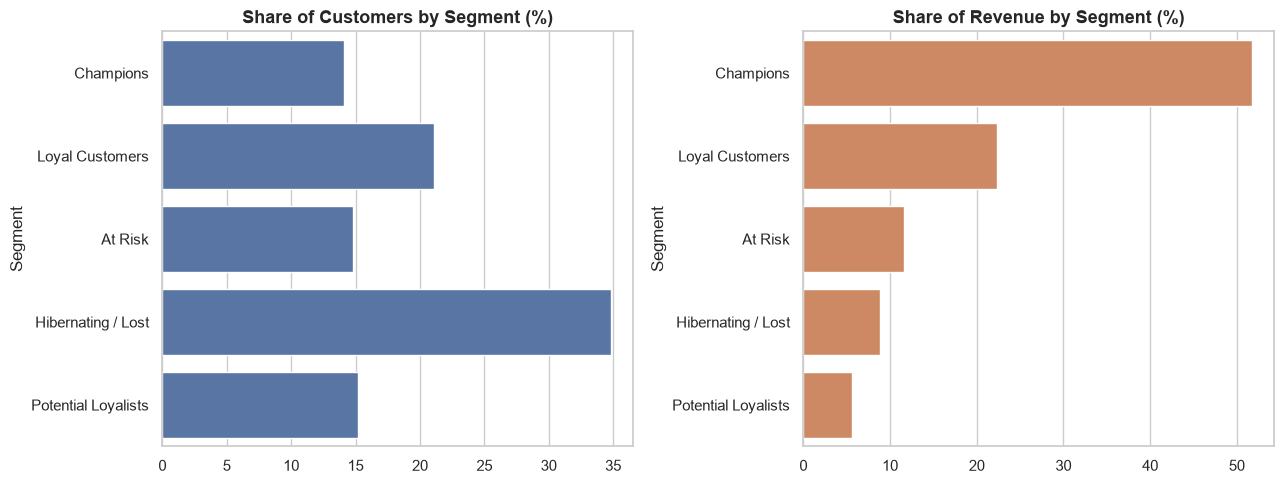

In [19]:
seg_summary = rfm.groupby("Segment").agg(
    Customers=("Segment", "count"),
    Revenue=("Monetary", "sum"),
).sort_values("Revenue", ascending=False)

seg_summary["Pct_Customers"] = (seg_summary["Customers"] / seg_summary["Customers"].sum() * 100).round(1)
seg_summary["Pct_Revenue"] = (seg_summary["Revenue"] / seg_summary["Revenue"].sum() * 100).round(1)

display(seg_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = seg_summary.index

sns.barplot(x=seg_summary["Pct_Customers"], y=order, ax=axes[0], color="#4C72B0")
axes[0].set_title("Share of Customers by Segment (%)")
axes[0].set_xlabel("")

sns.barplot(x=seg_summary["Pct_Revenue"], y=order, ax=axes[1], color="#DD8452")
axes[1].set_title("Share of Revenue by Segment (%)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

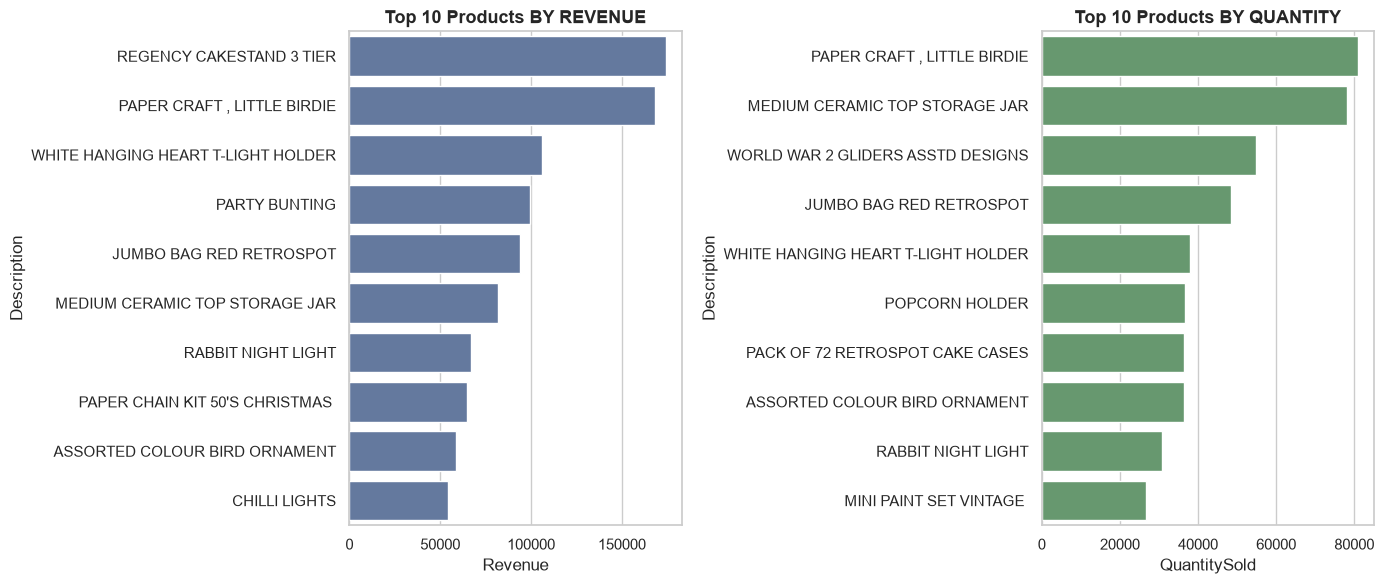

Products appearing in BOTH top-10 lists: 6 / 10


In [20]:
top_rev = df_sales.groupby("Description")["Revenue"].sum().nlargest(10)
top_qty = df_sales.groupby("Description")["Quantity"].sum().nlargest(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(x=top_rev.values, y=top_rev.index, ax=axes[0], color="#5B76A7")
axes[0].set_title("Top 10 Products BY REVENUE")
axes[0].set_xlabel("Revenue")

sns.barplot(x=top_qty.values, y=top_qty.index, ax=axes[1], color="#5FA06A")
axes[1].set_title("Top 10 Products BY QUANTITY")
axes[1].set_xlabel("QuantitySold")

plt.tight_layout()
plt.show()

common = len(set(top_rev.index) & set(top_qty.index))
print(f"Products appearing in BOTH top-10 lists: {common} / 10")

## 7. Product Analysis

**Business question:** Are the products that sell the most units also the products that generate the most revenue, and how concentrated is revenue across the catalog?

**"Most sold" and "most valuable" are not the same question.** A product that sells a huge *quantity*
at a few pence each may contribute far less revenue than a product that sells modestly but at a much
higher price. We compute both views side by side specifically to make that gap visible.

In [21]:
product_sales = (df_sales.groupby(['StockCode', 'Description'], dropna=False)
                 .agg(Revenue=('Revenue', 'sum'), Units=('Quantity', 'sum'),
                      Orders=('InvoiceNo', 'nunique'))
                 .sort_values('Revenue', ascending=False))
product_revenue_total = product_sales['Revenue'].sum()
top10_product_share = product_sales['Revenue'].head(10).sum() / product_revenue_total * 100
print(f'Top 10 products contribute {top10_product_share:.1f}% of merchandise revenue.')
display(product_sales.head(10))


Top 10 products contribute 9.4% of merchandise revenue.


,,Revenue,Units,Orders
StockCode,Description,,,
22423,REGENCY CAKESTAND 3 TIER,"174,156.54",13851,1988
23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,284.24",37580,2189
47566,PARTY BUNTING,"99,445.23",18283,1685
85099B,JUMBO BAG RED RETROSPOT,"94,159.81",48371,2089
23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92",78033,247
23084,RABBIT NIGHT LIGHT,"66,870.03",30739,994
22086,PAPER CHAIN KIT 50'S CHRISTMAS,"64,875.59",19329,1160
84879,ASSORTED COLOUR BIRD ORNAMENT,"58,927.62",36362,1455


Products in both the top-10 revenue and quantity rankings: 6 / 10


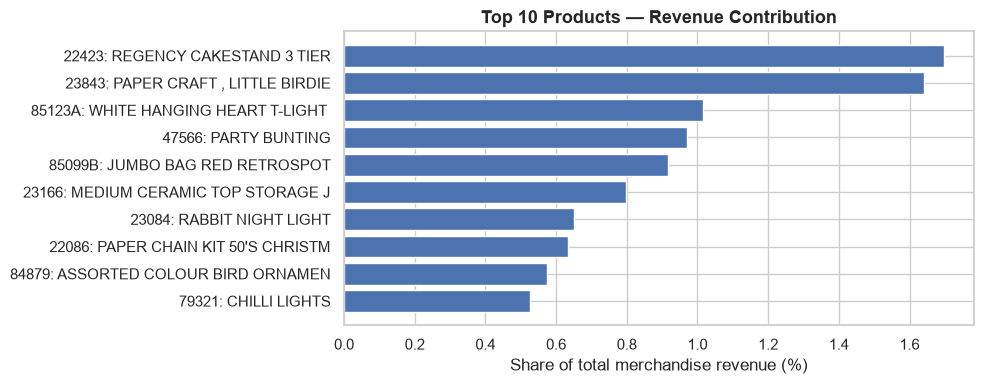

In [22]:
top10_revenue_codes = set(product_sales.nlargest(10, 'Revenue').index.get_level_values('StockCode'))
top10_units_codes = set(product_sales.nlargest(10, 'Units').index.get_level_values('StockCode'))
shared_top_products = len(top10_revenue_codes & top10_units_codes)
print(f'Products in both the top-10 revenue and quantity rankings: {shared_top_products} / 10')

fig, ax = plt.subplots(figsize=(10, 4))
shares = (product_sales['Revenue'].head(10) / product_revenue_total * 100).iloc[::-1]
ax.barh([f'{code}: {desc[:28]}' for code, desc in shares.index], shares.values)
ax.set(xlabel='Share of total merchandise revenue (%)', title='Top 10 Products — Revenue Contribution')
plt.tight_layout()
plt.show()


## 8. Time Analysis

**Business question:** When does sales revenue peak by month, weekday, hour, and weekend status?

We look at demand from four angles — month, weekday, hour, and weekend-vs-weekday — because "when is
demand high?" has a different answer depending on which calendar unit you're asking about, and each
answer implies a different operational decision (staffing vs. marketing calendar vs. server capacity).

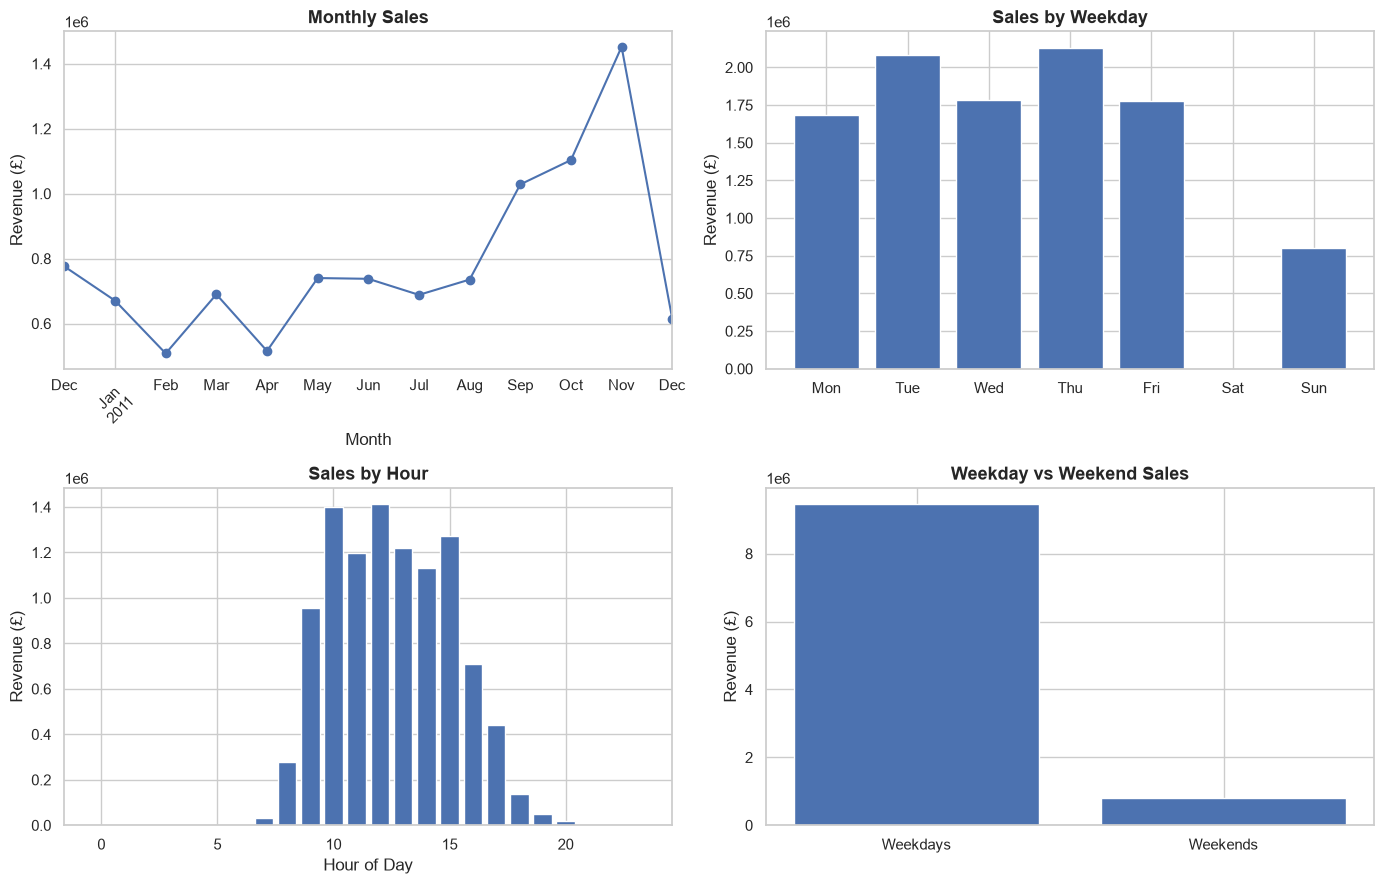

Peak sales month: 2011-11
Peak sales weekday: Thu
Peak sales hour: 12:00
Note: December 2010 and December 2011 are partial months; compare totals cautiously.


In [23]:
# Compare demand across month, weekday, hour and weekend status.
monthly_sales = df_sales.groupby(df_sales['InvoiceDate'].dt.to_period('M'))['Revenue'].sum()
weekday_sales = df_sales.groupby('DayofWeek')['Revenue'].sum().reindex(range(7), fill_value=0)
hourly_sales = df_sales.groupby('Hour')['Revenue'].sum().reindex(range(24), fill_value=0)
weekend_sales = df_sales.groupby('IsWeekend')['Revenue'].sum().reindex([False, True], fill_value=0)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
monthly_sales.plot(ax=axes[0, 0], marker='o')
axes[0, 0].set(title='Monthly Sales', xlabel='Month', ylabel='Revenue (£)')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 1].bar(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], weekday_sales.values)
axes[0, 1].set(title='Sales by Weekday', ylabel='Revenue (£)')
axes[1, 0].bar(hourly_sales.index, hourly_sales.values)
axes[1, 0].set(title='Sales by Hour', xlabel='Hour of Day', ylabel='Revenue (£)')
axes[1, 1].bar(['Weekdays', 'Weekends'], weekend_sales.values)
axes[1, 1].set(title='Weekday vs Weekend Sales', ylabel='Revenue (£)')
plt.tight_layout()
plt.show()
print('Peak sales month:', str(monthly_sales.idxmax()))
print('Peak sales weekday:', ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'][weekday_sales.idxmax()])
print('Peak sales hour:', f'{int(hourly_sales.idxmax()):02d}:00')
print('Note: December 2010 and December 2011 are partial months; compare totals cautiously.')


## 9. Country Analysis

**Business question:** Which countries are high-volume or high-value markets, and how does average order value vary?

The business is UK-based, so we expect the UK to dominate by sheer volume — the more interesting
question is which *other* countries behave differently: fewer customers but bigger baskets, for
instance, which would suggest a different kind of buyer (e.g. wholesale/resale) than the domestic
market.

In [24]:
country_sales = (df_sales.groupby('Country')
    .agg(Revenue=('Revenue', 'sum'), Units=('Quantity', 'sum'),
         Orders=('InvoiceNo', 'nunique'), Customers=('CustomerID', 'nunique'))
    .sort_values('Revenue', ascending=False))
country_sales['Average_Order_Value'] = country_sales['Revenue'] / country_sales['Orders']
country_sales['Revenue_Share_%'] = country_sales['Revenue'] / df_sales['Revenue'].sum() * 100
print('Country-level KPIs (sales include unidentified customers):')
display(country_sales.head(15).round(2))


Country-level KPIs (sales include unidentified customers):


,Revenue,Units,Orders,Customers,Average_Order_Value,Revenue_Share_%
Country,,,,,,
United Kingdom,"8,736,191.54",4639145,17902,3916,488.00,85.16
Netherlands,"283,889.34",200258,93,9,"3,052.57",2.77
EIRE,"270,850.86",146896,282,3,960.46,2.64
Germany,"205,381.15",118032,443,94,463.61,2.00
France,"184,493.00",111226,382,87,482.97,1.80
Australia,"138,103.81",83890,56,9,"2,466.14",1.35
Spain,"55,706.56",27724,88,30,633.03,0.54
Switzerland,"53,065.60",30515,50,21,"1,061.31",0.52
Japan,"37,416.37",26016,19,8,"1,969.28",0.36


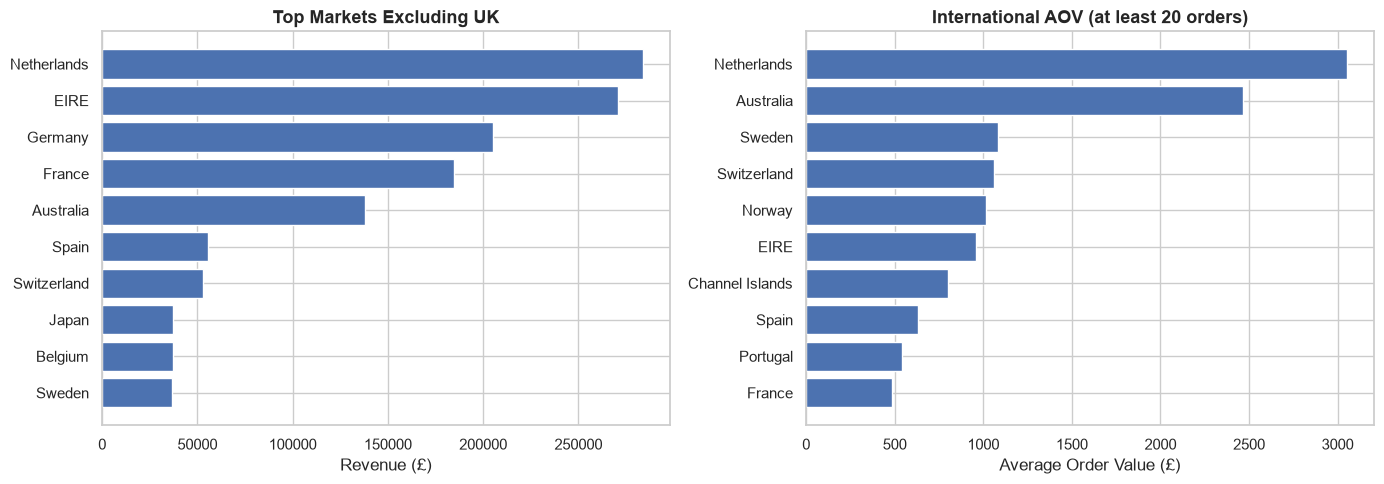

In [25]:
non_uk = country_sales.drop(index='United Kingdom', errors='ignore')
top_intl = non_uk.head(10).sort_values('Revenue')
# Avoid treating countries with 1–2 orders as representative for AOV.
aov_candidates = non_uk.loc[non_uk['Orders'] >= 20].nlargest(10, 'Average_Order_Value')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(top_intl.index, top_intl['Revenue'])
axes[0].set(title='Top Markets Excluding UK', xlabel='Revenue (£)')
axes[1].barh(aov_candidates.sort_values('Average_Order_Value').index,
             aov_candidates.sort_values('Average_Order_Value')['Average_Order_Value'])
axes[1].set(title='International AOV (at least 20 orders)', xlabel='Average Order Value (£)')
plt.tight_layout()
plt.show()


## 10. Customer Behavior Relationships

**Business question:** How are customer recency, order frequency, revenue, and average order value related?

Do the RFM dimensions move together, or are they independent? We check with correlation — remembering
throughout that **correlation is not causation**: a strong Frequency–Monetary correlation does not
prove that ordering more often *causes* higher spend; both could simply be expressions of the same
underlying engagement level.

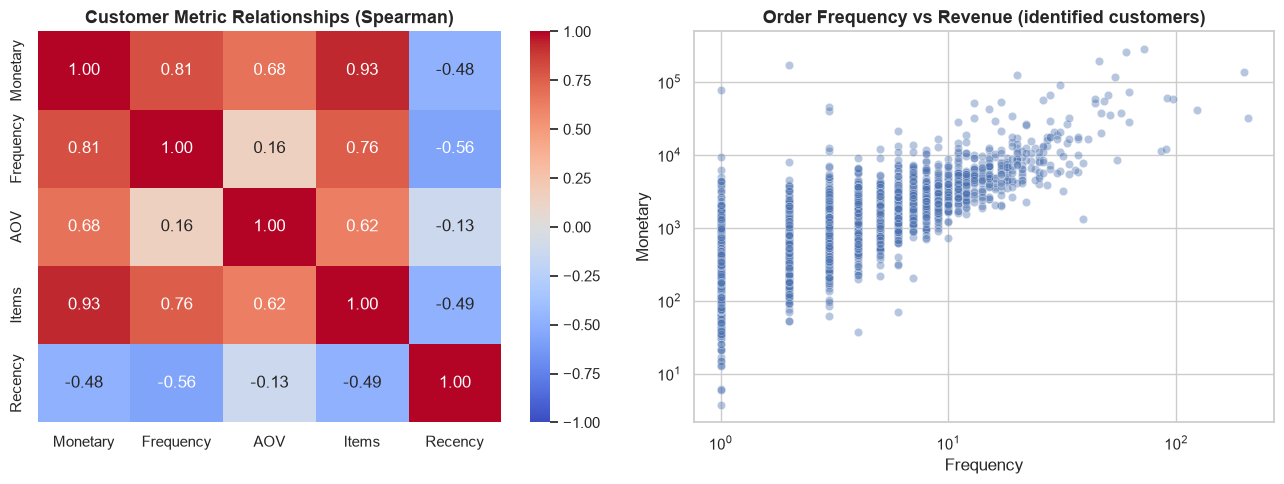

Correlations describe association, not causation.


In [26]:
customer_behavior = customer_df[['total_revenue', 'num_of_orders', 'average_order_value', 'num_of_items']].copy()
customer_behavior['Recency'] = (snap_date - customer_df['last_purchases']).dt.days
customer_behavior = customer_behavior.rename(columns={
    'total_revenue': 'Monetary', 'num_of_orders': 'Frequency',
    'average_order_value': 'AOV', 'num_of_items': 'Items'
})
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(customer_behavior.corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Customer Metric Relationships (Spearman)')
sns.scatterplot(data=customer_behavior, x='Frequency', y='Monetary', alpha=.4, ax=axes[1])
axes[1].set(xscale='log', yscale='log', title='Order Frequency vs Revenue (identified customers)')
plt.tight_layout()
plt.show()
print('Correlations describe association, not causation.')


## 11. Product Co-Purchase Analysis

**Business question:** Which products appear together on invoices often enough to consider bundles or cross-selling?

**Which products tend to appear on the same invoice?** We answer this with plain Pandas — counting
co-occurring pairs directly — rather than an association-rule-mining library (Apriori/FP-Growth), to
keep the technique fully transparent and inspectable.

- **Support** = (number of invoices containing BOTH products) / (total invoices). It tells us how
  *common* the pair is overall — **it does not tell us one product caused the purchase of the other.**

In [27]:
from itertools import combinations
from collections import Counter
invoice_products = df_sales.groupby('InvoiceNo')['StockCode'].agg(lambda s: set(s.dropna()))
popular_codes = set(df_sales.groupby('StockCode')['InvoiceNo'].nunique().nlargest(100).index)
pair_counts = Counter()
for products in invoice_products:
    selected = sorted(products & popular_codes)
    pair_counts.update(combinations(selected, 2))

num_invoices = len(invoice_products)
product_names = (df_sales.drop_duplicates('StockCode')
                 .set_index('StockCode')['Description'].astype(str).to_dict())
top_pairs = pd.DataFrame([
    {'Product A': product_names.get(a, a), 'Product B': product_names.get(b, b),
     'Invoices Together': count, 'Support (%)': count / num_invoices * 100}
    for (a, b), count in pair_counts.most_common(15)
])
print(f'Pair candidates: 100 frequently purchased products; denominator: {num_invoices:,} positive-sale invoices.')
display(top_pairs)
print('Support is co-occurrence frequency, not proof of a cross-sell effect.')


Pair candidates: 100 frequently purchased products; denominator: 19,774 positive-sale invoices.


,Product A,Product B,Invoices Together,Support (%)
0,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,825,4.17
1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,767,3.88
2,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,724,3.66
3,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,680,3.44
4,LUNCH BAG RED RETROSPOT,LUNCH BAG SUKI DESIGN,655,3.31
5,LUNCH BAG RED RETROSPOT,LUNCH BAG BLACK SKULL.,641,3.24
6,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,640,3.24
7,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,632,3.20
8,LUNCH BAG RED RETROSPOT,LUNCH BAG PINK POLKADOT,606,3.06
9,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,598,3.02


Support is co-occurrence frequency, not proof of a cross-sell effect.


## 12. Outlier Analysis

**Business question:** Which unusually large quantities, prices, and revenues need investigation, and which may be legitimate wholesale orders?

We use the **IQR method**: any value below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR` is flagged. Flagging
is not the same as deleting — remember the wholesaler context from Section 1: some "outliers" here are
completely legitimate, large, valuable transactions.

In [28]:
outlier_summary = []
for field in ['Quantity', 'UnitPrice', 'Revenue']:
    q1, q3 = df_sales[field].quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flag = df_sales[field].lt(lower) | df_sales[field].gt(upper)
    outlier_summary.append({'Metric': field, 'Lower fence': lower,
                            'Upper fence': upper, 'Flagged lines': int(flag.sum()),
                            'Flagged %': round(flag.mean() * 100, 2)})
outlier_table = pd.DataFrame(outlier_summary)
display(outlier_table)


,Metric,Lower fence,Upper fence,Flagged lines,Flagged %
0,Quantity,-15.50,28.50,26815,5.13
1,UnitPrice,-3.07,8.45,35773,6.85
2,Revenue,-16.80,38.40,41125,7.87


Largest invoices by positive merchandise revenue (review, do not auto-delete):


,Revenue,Units,Product_Lines
InvoiceNo,,,
581483,"168,469.60",80995,1
541431,"77,183.60",74215,1
574941,"52,940.94",14149,101
576365,"50,653.91",13956,99
556444,"38,970.00",60,1
567423,"31,698.16",12572,12
556917,"22,775.93",15049,138
572209,"22,206.00",1920,7
567381,"22,104.80",6760,12


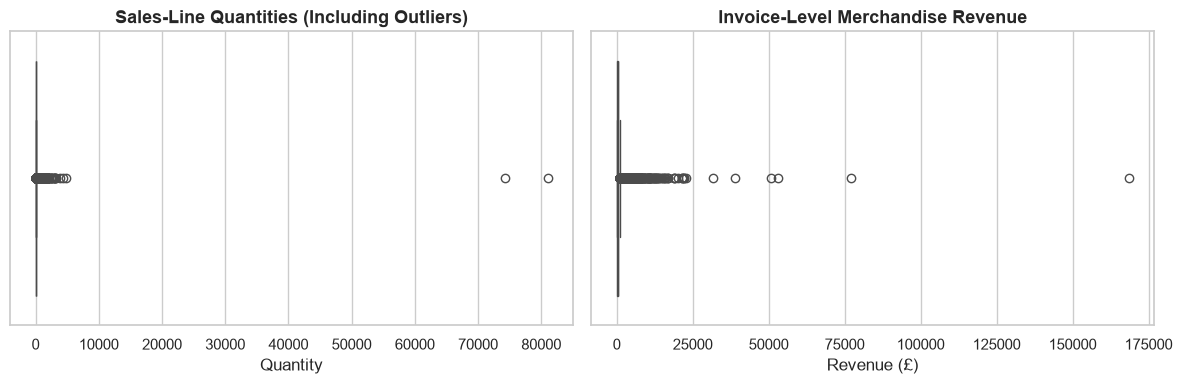

In [29]:
order_totals = (df_sales.groupby('InvoiceNo')
                .agg(Revenue=('Revenue', 'sum'), Units=('Quantity', 'sum'),
                     Product_Lines=('StockCode', 'size'))
                .sort_values('Revenue', ascending=False))
print('Largest invoices by positive merchandise revenue (review, do not auto-delete):')
display(order_totals.head(10))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_sales['Quantity'], ax=axes[0])
axes[0].set(title='Sales-Line Quantities (Including Outliers)', xlabel='Quantity')
sns.boxplot(x=order_totals['Revenue'], ax=axes[1])
axes[1].set(title='Invoice-Level Merchandise Revenue', xlabel='Revenue (£)')
plt.tight_layout()
plt.show()


## 13. Key Findings

**Business question:** What evidence-based actions should the business consider based on the results above?

Each finding follows **Observation → Evidence → Interpretation → Business Implication**. All numbers
below are pulled live from the analysis above, not hand-typed, so they will always match this run.

In [30]:
total_revenue = df_sales['Revenue'].sum()
total_orders = df_sales['InvoiceNo'].nunique()
peak_month = str(monthly_sales.idxmax())
top_product_code, top_product_desc = product_sales.index[0]
top_product_revenue = product_sales.iloc[0]['Revenue']
leading_segment = seg_summary['Revenue'].idxmax()
leading_segment_share = seg_summary.loc[leading_segment, 'Pct_Revenue']
intl_market = non_uk.index[0] if len(non_uk) else 'Not available'

print('OBSERVATION 1 — SALES CONCENTRATION')
print(f'The 10 largest products produce {top10_product_share:.1f}% of total merchandise revenue.')
print(f'Top revenue-generating item: {top_product_desc} ({top_product_code}); £{top_product_revenue:,.2f}.')
print('ACTION: Prioritize availability of leading products; review gross profit before acting.')
print('\nOBSERVATION 2 — CUSTOMER VALUE')
print(f'{leading_segment} account for {leading_segment_share:.1f}% of identified-customer revenue.')
print('ACTION: Test targeted retention or loyalty offers; sales alone cannot establish profitability.')
print('\nOBSERVATION 3 — TIMING AND INTERNATIONAL DEMAND')
print(f'Highest observed monthly revenue: {peak_month}. Leading non-UK market: {intl_market}.')
print('ACTION: Investigate campaign timing and country-specific fulfillment needs.')


OBSERVATION 1 — SALES CONCENTRATION
The 10 largest products produce 9.4% of total merchandise revenue.
Top revenue-generating item: REGENCY CAKESTAND 3 TIER (22423); £174,156.54.
ACTION: Prioritize availability of leading products; review gross profit before acting.

OBSERVATION 2 — CUSTOMER VALUE
Champions account for 51.7% of identified-customer revenue.
ACTION: Test targeted retention or loyalty offers; sales alone cannot establish profitability.

OBSERVATION 3 — TIMING AND INTERNATIONAL DEMAND
Highest observed monthly revenue: 2011-11. Leading non-UK market: Netherlands.
ACTION: Investigate campaign timing and country-specific fulfillment needs.


## 14. Limitations and Additional Data

- **Revenue is not profit:** product costs, shipping fees, and returns-processing costs are unavailable. Gross margin data is needed for profitability decisions.
- **Unidentified customers:** missing `CustomerID` records contribute to product and country sales but cannot be assigned to customer segments.
- **Partial months:** the dataset begins in December 2010 and ends in December 2011, so month-to-month totals must be interpreted with care.
- **Cancellations and returns:** excluded from positive-merchandise sales; a separate net-sales and refund analysis would need matched return/credit information.
- **Co-purchase ≠ causation:** item pairs are descriptive; controlled tests are needed to judge promotion effectiveness.
- **Single business, historical data:** findings are not automatically transferable to other shops or years.


## 15. Executive Summary

The cell below produces a **current, data-backed summary** using the metrics calculated above. It reports three findings, a suggested action, and two major limitations without inventing numbers.


In [31]:
print('ONLINE RETAIL — EXECUTIVE SUMMARY')
print(f'Analyzed {total_orders:,} positive-sale invoices, worth £{total_revenue:,.2f} in merchandise revenue.')
print(f'1) Top 10 products represent {top10_product_share:.1f}% of revenue.')
print(f'2) {leading_segment} represent {leading_segment_share:.1f}% of known-customer revenue.')
print(f'3) The strongest observed month was {peak_month}; the leading non-UK market was {intl_market}.')
print('Recommendation: Investigate stock availability and segment-specific retention campaigns.')
print('Limitations: No costs/margins; anonymous buyers cannot be linked to individual customers.')
print('Partial months and the single-retailer sample restrict time-based generalization.')


ONLINE RETAIL — EXECUTIVE SUMMARY
Analyzed 19,774 positive-sale invoices, worth £10,258,967.19 in merchandise revenue.
1) Top 10 products represent 9.4% of revenue.
2) Champions represent 51.7% of known-customer revenue.
3) The strongest observed month was 2011-11; the leading non-UK market was Netherlands.
Recommendation: Investigate stock availability and segment-specific retention campaigns.
Limitations: No costs/margins; anonymous buyers cannot be linked to individual customers.
Partial months and the single-retailer sample restrict time-based generalization.


## Appendix — Saving Outputs for the Dashboard

These optional CSV exports preserve the cleaned sales, customer, segment and country summaries from this notebook. The six-panel Matplotlib dashboard below **uses the in-memory tables directly**; it does not require a separate Dash application.


In [32]:
from pathlib import Path
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)
df_sales.to_csv(output_dir / 'retail_clean_sales.csv', index=False)
customer_df.to_csv(output_dir / 'retail_customer_summary.csv', index=False)
rfm.to_csv(output_dir / 'retail_rfm_segments.csv')
country_sales.to_csv(output_dir / 'retail_country_summary.csv')
print('Saved retail analysis tables to:', output_dir.resolve())


Saved retail analysis tables to: C:\Users\malak\Desktop\projects\outputs


## 16.  Sales Dashboard

**Business question:** Can a manager scan the main sales signals in one view? This is the original intended 


In [33]:
from dash import Dash, dcc, html, Input, Output
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

sales = df_sales.copy()
sales["InvoiceDate"] = pd.to_datetime(
    sales["InvoiceDate"], errors="coerce"
)
sales["Revenue"] = pd.to_numeric(
    sales["Revenue"], errors="coerce"
)
sales = sales.dropna(subset=["InvoiceDate", "Revenue"])
sales["Year"] = sales["InvoiceDate"].dt.year
sales["Weekday"] = sales["InvoiceDate"].dt.dayofweek
sales["Hour"] = sales["InvoiceDate"].dt.hour

# CUSTOM COLOR PALETTE
C = {
    "bg": "#211D1A",
    "panel": "#302923",
    "text": "#F9EEDF",
    "muted": "#C4B5A3",
    "terra": "#D99572",
    "olive": "#A9B17C",
    "rose": "#C78C8D",
    "gold": "#E3BB79",
    "grid": "#50463D"
}
accents = [C["terra"], C["olive"], C["rose"], C["gold"]]

def style(fig, height=355):
    fig.update_layout(
        template="plotly_dark",
        paper_bgcolor=C["panel"],
        plot_bgcolor=C["panel"],
        font=dict(color=C["text"], family="Trebuchet MS, Arial"),
        title_font=dict(size=17),
        height=height,
        margin=dict(l=35, r=25, t=60, b=45),
        colorway=accents,
        legend=dict(orientation="h", y=-0.25),
        hoverlabel=dict(
            bgcolor=C["bg"], font_color=C["text"]
        )
    )
    fig.update_xaxes(gridcolor=C["grid"])
    fig.update_yaxes(gridcolor=C["grid"])
    return fig

def metric(label, component_id, color):
    return html.Div([
        html.Div(
            label,
            style={"fontSize": "12px", "color": C["muted"]}
        ),
        html.H2(
            id=component_id,
            style={"margin": "9px 0 0", "color": color}
        )
    ], style={
        "background": C["panel"],
        "padding": "21px",
        "borderRadius": "15px",
        "borderTop": f"3px solid {color}",
        "flex": "1",
        "minWidth": "165px"
    })

def panel(graph_id):
    return html.Div(
        dcc.Graph(
            id=graph_id,
            config={"displaylogo": False}
        ),
        style={
            "background": C["panel"],
            "borderRadius": "15px",
            "overflow": "hidden"
        }
    )

retail_app = Dash("retail_sales_dashboard")

retail_app.layout = html.Div([
    html.Div([
        html.Div(
            "COMMERCE / ANALYTICS",
            style={
                "letterSpacing": "3px",
                "color": C["terra"],
                "fontSize": "12px"
            }
        ),
        html.H1(
            "Online Retail Sales | Interactive Dashboard",
            style={"margin": "8px 0"}
        ),
        html.P(
            "Explore revenue, orders, products, countries and customer segments.",
            style={"color": C["muted"], "margin": "0"}
        )
    ], style={"padding": "16px 0 24px"}),

    # INTERACTIVE FILTERS
    html.Div([
        html.Div([
            html.Label("Country"),
            dcc.Dropdown(
                id="ret-country",
                options=[
                    {"label": "All countries", "value": "ALL"}
                ] + [
                    {"label": c, "value": c}
                    for c in sorted(
                        sales["Country"].dropna().astype(str).unique()
                    )
                ],
                value="ALL",
                clearable=False,
                style={"color": "#292520"}
            )
        ], style={"flex": "2", "minWidth": "200px"}),

        html.Div([
            html.Label("Year"),
            dcc.Dropdown(
                id="ret-year",
                options=[
                    {"label": "All years", "value": "ALL"}
                ] + [
                    {"label": str(y), "value": str(y)}
                    for y in sorted(sales["Year"].dropna().unique())
                ],
                value="ALL",
                clearable=False,
                style={"color": "#292520"}
            )
        ], style={"flex": "1", "minWidth": "150px"}),

        html.Div([
            html.Label("Top products"),
            dcc.Dropdown(
                id="ret-top",
                options=[5, 10, 15],
                value=10,
                clearable=False,
                style={"color": "#292520"}
            )
        ], style={"flex": "1", "minWidth": "150px"})

    ], style={
        "display": "flex",
        "flexWrap": "wrap",
        "gap": "16px",
        "padding": "19px",
        "background": C["panel"],
        "borderRadius": "14px",
        "marginBottom": "19px"
    }),

    # KPI CARDS
    html.Div([
        metric("REVENUE", "ret-revenue", C["terra"]),
        metric("ORDERS", "ret-orders", C["olive"]),
        metric("CUSTOMERS", "ret-customers", C["rose"]),
        metric("AVG. ORDER VALUE", "ret-aov", C["gold"])
    ], style={
        "display": "flex",
        "flexWrap": "wrap",
        "gap": "13px",
        "marginBottom": "20px"
    }),

    # CHARTS
    html.Div([
        panel("ret-trend"),
        panel("ret-products"),
        panel("ret-countries"),
        panel("ret-segments"),
        panel("ret-heatmap")
    ], style={
        "display": "grid",
        "gridTemplateColumns": "repeat(auto-fit, minmax(360px, 1fr))",
        "gap": "17px"
    }),

    html.P(
        "Revenue excludes cancellations. RFM segment labels use full-history data.",
        style={
            "color": C["muted"],
            "fontSize": "12px",
            "marginTop": "22px"
        }
    )
], style={
    "background": C["bg"],
    "color": C["text"],
    "fontFamily": "Trebuchet MS, Arial",
    "padding": "24px",
    "minHeight": "100vh"
})


# INTERACTIVE CALLBACK
@retail_app.callback(
    Output("ret-revenue", "children"),
    Output("ret-orders", "children"),
    Output("ret-customers", "children"),
    Output("ret-aov", "children"),
    Output("ret-trend", "figure"),
    Output("ret-products", "figure"),
    Output("ret-countries", "figure"),
    Output("ret-segments", "figure"),
    Output("ret-heatmap", "figure"),
    Input("ret-country", "value"),
    Input("ret-year", "value"),
    Input("ret-top", "value")
)
def update_retail(country, year, top_n):
    d = sales

    if country != "ALL":
        d = d[d["Country"].astype(str) == country]

    if year != "ALL":
        d = d[d["Year"] == int(year)]

    # KPIs
    revenue = d["Revenue"].sum()
    orders = d["InvoiceNo"].nunique()
    customers = d["CustomerID"].nunique()
    aov = revenue / orders if orders else 0

    # MONTHLY REVENUE
    monthly = (
        d.groupby(
            pd.Grouper(key="InvoiceDate", freq="MS")
        )["Revenue"].sum().reset_index()
    )

    trend = px.area(
        monthly,
        x="InvoiceDate",
        y="Revenue",
        title="Revenue Over Time"
    )
    trend.update_traces(
        line_color=C["terra"],
        fillcolor="rgba(217,149,114,.20)",
        hovertemplate=(
            "%{x|%b %Y}<br>£%{y:,.2f}<extra></extra>"
        )
    )

    # TOP PRODUCTS
    top_products = (
        d.groupby("Description", dropna=True)["Revenue"]
        .sum()
        .nlargest(int(top_n))
        .sort_values()
        .reset_index()
    )

    products = px.bar(
        top_products,
        x="Revenue",
        y="Description",
        orientation="h",
        title=f"Top {top_n} Products by Revenue",
        color_discrete_sequence=[C["olive"]]
    )
    products.update_layout(yaxis=dict(automargin=True))

    # COUNTRY REVENUE
    countries = (
        d.groupby("Country")["Revenue"]
        .sum()
        .nlargest(8)
        .sort_values()
        .reset_index()
    )

    country_fig = px.bar(
        countries,
        x="Revenue",
        y="Country",
        orientation="h",
        title="Revenue by Country",
        color_discrete_sequence=[C["gold"]]
    )

    # CUSTOMER SEGMENTATION
    if "rfm" in globals() and "Segment" in rfm.columns:
        seg = d.assign(
            Segment=d["CustomerID"]
            .map(rfm["Segment"])
            .fillna("Unidentified")
        )
        seg_data = (
            seg.groupby("Segment")["Revenue"]
            .sum()
            .reset_index()
        )
    else:
        seg_data = pd.DataFrame({
            "Segment": ["Not available"],
            "Revenue": [0]
        })

    segments = px.pie(
        seg_data,
        names="Segment",
        values="Revenue",
        hole=0.65,
        title="Revenue by Customer Segment",
        color_discrete_sequence=accents
    )
    segments.update_traces(
        textinfo="percent+label",
        textposition="outside"
    )

    # SALES HEATMAP
    heat_data = (
        d.groupby(["Weekday", "Hour"])["Revenue"]
        .sum()
        .unstack(fill_value=0)
        .reindex(
            index=range(7),
            columns=range(24),
            fill_value=0
        )
    )

    heat = go.Figure(go.Heatmap(
        z=heat_data.values,
        x=list(range(24)),
        y=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
        colorscale=[
            [0, C["panel"]],
            [0.35, C["rose"]],
            [0.7, C["terra"]],
            [1, C["gold"]]
        ],
        hovertemplate=(
            "%{y} at %{x}:00"
            "<br>Revenue: £%{z:,.0f}<extra></extra>"
        )
    ))
    heat.update_layout(
        title="Revenue Heatmap · Day × Hour",
        xaxis_title="Hour of Day"
    )

    return (
        f"£{revenue:,.0f}",
        f"{orders:,}",
        f"{customers:,}",
        f"£{aov:,.2f}",
        style(trend),
        style(products, 420),
        style(country_fig),
        style(segments),
        style(heat)
    )


retail_app.run(
    debug=False,
    port=8050,
    jupyter_mode="inline"
)

### Dashboard interpretation

The charts describe **positive merchandise sales**, not profit or net sales after returns. The non-UK view excludes the UK only for readability, and segment revenue includes identified customers only. The dashboard is a static overview and updates when the notebook runs again.
